# Embedding an image with EmbeddingGemma 2

A multimodal embedding model puts text and images into one 768-dimensional space

In [1]:
import numpy as np
import torch
import matplotlib.pyplot as plt

from PIL import Image
from sentence_transformers import SentenceTransformer

## Load the model

Google recommends `bfloat16` or `float32`, never `float16`

In [2]:
dtype = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float32

model = SentenceTransformer("google/embeddinggemma-2", model_kwargs={"torch_dtype": dtype})

print(model.get_embedding_dimension())

Loading weights:   0%|          | 0/1376 [00:00<?, ?it/s]

768


## Load one image

from the STL-10.

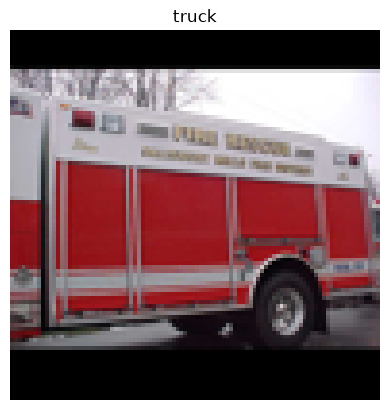

In [19]:
DATA = "../week_2/data/stl10_binary"

class_names = [l.strip() for l in open(f"{DATA}/class_names.txt") if l.strip()]

X = np.fromfile(f"{DATA}/test_X.bin", dtype=np.uint8).reshape(-1, 3, 96, 96)
X = X.transpose(0, 3, 2, 1)
y = np.fromfile(f"{DATA}/test_y.bin", dtype=np.uint8)

i = 34
img = Image.fromarray(X[i])

plt.imshow(img)
plt.title(class_names[y[i] - 1])
plt.axis("off")
plt.show()

## The embedding

An image goes in as a dict. No text prefix - the `task: ...` prefixes are for text only.

In [20]:
e = model.encode({"image": img}, normalize_embeddings=True)

print(e.shape, e.dtype)

(768,) float32


In [21]:
e.shape

(768,)

## Construct text from the class label

This is just to show that what a plain vision transformer cannot do. 
The image vector is compared against
the embedding of each class name.

In [22]:
texts = [f"a photo of a {c}" for c in class_names]

print (texts)

T = model.encode(texts, normalize_embeddings=True)

scores = e @ T.T

for rank in np.argsort(-scores)[:3]:
    print(f"{scores[rank]:+.3f}  {class_names[rank]}")

print(f"\ntrue class: {class_names[y[i] - 1]}")

['a photo of a airplane', 'a photo of a bird', 'a photo of a car', 'a photo of a cat', 'a photo of a deer', 'a photo of a dog', 'a photo of a horse', 'a photo of a monkey', 'a photo of a ship', 'a photo of a truck']
+0.630  truck
+0.585  car
+0.585  ship

true class: truck


## The same 1,000 images as the other notebooks

`embeddings_stl10_1000.npz` lists which images the course has been using all along, so the
vectors here are directly comparable with the ViT and autoencoder ones.

In [ ]:
d = np.load("../week_2/data/embeddings_stl10_1000.npz")
idx, y1000 = d["idx"], d["y"]

X_all = np.concatenate([
    np.fromfile(f"{DATA}/train_X.bin", dtype=np.uint8).reshape(-1, 3, 96, 96),
    np.fromfile(f"{DATA}/test_X.bin", dtype=np.uint8).reshape(-1, 3, 96, 96),
]).transpose(0, 3, 2, 1)

imgs = [Image.fromarray(im) for im in X_all[idx]]

import time

t0 = time.perf_counter()
E = model.encode([{"image": im} for im in imgs], batch_size=32, normalize_embeddings=True)
dt = time.perf_counter() - t0

print(E.shape, f"{dt:.1f}s for {len(imgs)} images")

## Closest and farthest

Cosine similarity against every other image, then the five nearest and the five farthest.

In [ ]:
q = 0

sims = E @ E[q]

others = np.arange(len(E)) != q
order = np.argsort(sims[others])[::-1]
at = np.where(others)[0]

nearest = at[order[:5]]
farthest = at[order[-5:][::-1]]

print(f"query: {q}  ({class_names[y1000[q] - 1]})\n")

for tag, ids in (("nearest", nearest), ("farthest", farthest)):
    print(tag)
    for j in ids:
        print(f"  {class_names[y1000[j] - 1]:12} {sims[j]:+.3f}")
    print()

fig, axes = plt.subplots(2, 6, figsize=(15, 5.2))

for ax in axes.ravel():
    ax.axis("off")

axes[0, 0].imshow(imgs[q])
axes[0, 0].set_title(f"query\n{class_names[y1000[q] - 1]}", fontsize=8)

for ax, j in zip(axes[0, 1:], nearest):
    ax.imshow(imgs[j])
    ax.set_title(f"{class_names[y1000[j] - 1]}\n{sims[j]:+.2f}", fontsize=8)

for ax, j in zip(axes[1, 1:], farthest):
    ax.imshow(imgs[j])
    ax.set_title(f"{class_names[y1000[j] - 1]}\n{sims[j]:+.2f}", fontsize=8)

axes[1, 0].text(0.5, 0.5, "farthest", rotation=90, ha="center", va="center", fontsize=10)

plt.tight_layout()
plt.show()